# BIL545 - Proje 1
## Banka Pazarlamasında Abonelik Tahmini

### Bölüm 1 - Veri, Ön İşleme ve Veri Sızıntısı

Bu çalışmada UCI Bank Marketing veri kümesi
kullanılarak müşterilerin vadeli mevduata abonelik
durumları incelenecektir.

Amaç, veri kümesini tanımak, veri ön işleme
yöntemlerini değerlendirmek ve veri sızıntısının
model sonuçlarına etkisini araştırmaktır.

In [1]:
import sys
import random
import numpy as np
import pandas as pd
import sklearn
import scipy

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Random seed:", SEED)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
SciPy: 1.16.3
Random seed: 42


## 1. Veri Kümesinin Yüklenmesi

Bu projede UCI Machine Learning Repository üzerinden
sağlanan Bank Marketing veri kümesi kullanılmaktadır.

Veri kümesi, Portekiz'deki bir bankanın telefon
pazarlama kampanyalarına ait kayıtları içermektedir.

Hedef değişken `y`, müşterinin vadeli mevduata
abone olup olmadığını göstermektedir.

Veri dosyası GitHub deposuna eklenmeyecek,
Google Colab ortamına ayrıca yüklenecektir.

In [2]:
from pathlib import Path
from google.colab import files

# Veri dosyasının konumu
dosya_yolu = Path("/content/bank-full.csv")

# Dosya bulunmuyorsa kullanıcıdan yüklemesini iste
if not dosya_yolu.exists():
    print("Lütfen bank-full.csv dosyasını yükleyin.")
    files.upload()

# Dosyanın varlığını kontrol et
if not dosya_yolu.exists():
    raise FileNotFoundError("bank-full.csv bulunamadı.")

# Veri kümesini oku
df = pd.read_csv(dosya_yolu, sep=";")

# Temel bilgileri göster
print("Satır sayısı:", df.shape[0])
print("Sütun sayısı:", df.shape[1])
print("Sütunlar:", df.columns.tolist())

display(df.head())

Lütfen bank-full.csv dosyasını yükleyin.


Saving bank-full.csv to bank-full.csv
Satır sayısı: 45211
Sütun sayısı: 17
Sütunlar: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 2. Keşifsel Veri Analizi (EDA)

Bu bölümde veri kümesinin yapısı, değişken türleri,
hedef değişkenin dağılımı ve yinelenen kayıtlar
incelenecektir.

Amaç, model geliştirmeden önce verinin temel
özelliklerini ve olası problemlerini belirlemektir.

In [3]:
# Veri kümesinin boyutları
print("Veri kümesinin boyutu:", df.shape)

# Değişkenlerin veri tipleri
print("\nDeğişken tipleri:")
display(df.dtypes.to_frame(name="Veri tipi"))

# Hedef değişkenin dağılımı
print("\nHedef değişken dağılımı:")

hedef_dagilimi = pd.DataFrame({
    "Adet": df["y"].value_counts(),
    "Oran (%)": df["y"].value_counts(normalize=True) * 100
})

display(hedef_dagilimi.round(2))

# Yinelenen satır kontrolü
print("\nYinelenen satır sayısı:", df.duplicated().sum())

Veri kümesinin boyutu: (45211, 17)

Değişken tipleri:


,Veri tipi
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Hedef değişken dağılımı:


,Adet,Oran (%)
y,,
no,39922,88.3
yes,5289,11.7



Yinelenen satır sayısı: 0


### Yorum - İlk Veri İncelemesi

Veri kümesinde 45.211 gözlem ve 17 değişken bulunmaktadır.
Bunların 16'sı girdi değişkeni, biri hedef değişken olan
y sütunudur.

Değişkenlerin 7'si int64, 10'u object veri tipindedir.
Ancak bu tipler değişkenlerin ölçüm ölçeklerini
doğrudan göstermemektedir.

Hedef değişken incelendiğinde kayıtların %88,30'unun
abonelikle sonuçlanmadığı, %11,70'inin ise abonelikle
sonuçlandığı görülmektedir.

Bu dağılım, sınıflar arasında belirgin bir dengesizlik
olduğunu göstermektedir. Bu nedenle model
değerlendirmesinde yalnızca doğruluk (accuracy)
ölçütü yeterli olmayacaktır.

Veri kümesinde birebir yinelenen satır bulunmamıştır.
Bununla birlikte müşteri kimlikleri mevcut olmadığından
aynı müşterinin farklı kampanya kayıtlarında
bulunup bulunmadığı belirlenememektedir.

## 3. Öznitelik Bazında Veri Kalitesi Analizi

Bu bölümde her değişkenin saklama tipi, eksik değer oranı,
farklı değer sayısı ve sıfır oranı incelenmektedir.

Amaç, veri ön işleme aşamasından önce olası veri kalitesi
problemlerini belirlemektir.

In [4]:
# Her öznitelik için veri kalitesi bilgileri
kalite_sonuclari = []

for sutun in df.columns:

    # Sütunun saklama tipi
    veri_tipi = str(df[sutun].dtype)

    # Gerçek NaN değerlerinin oranı
    eksik_orani = df[sutun].isna().mean() * 100

    # Farklı değer sayısı
    farkli_deger = df[sutun].nunique(dropna=True)

    # Sıfır oranı (yalnızca sayısal değişkenlerde)
    if pd.api.types.is_numeric_dtype(df[sutun]):
        sifir_orani = (df[sutun] == 0).mean() * 100
    else:
        sifir_orani = float("nan")

    kalite_sonuclari.append({
        "Öznitelik": sutun,
        "Saklama tipi": veri_tipi,
        "Eksik oranı (%)": eksik_orani,
        "Farklı değer sayısı": farkli_deger,
        "Sıfır oranı (%)": sifir_orani
    })

# Sonuçları tabloya dönüştür
kalite_tablosu = pd.DataFrame(kalite_sonuclari)

display(kalite_tablosu.round(2))

,Öznitelik,Saklama tipi,Eksik oranı (%),Farklı değer sayısı,Sıfır oranı (%)
0,age,int64,0.0,77,0.00
1,job,object,0.0,12,NaN
2,marital,object,0.0,3,NaN
3,education,object,0.0,4,NaN
4,default,object,0.0,2,NaN
5,balance,int64,0.0,7168,7.77
6,housing,object,0.0,2,NaN
7,loan,object,0.0,2,NaN
8,contact,object,0.0,3,NaN
9,day,int64,0.0,31,0.00


In [5]:
# Kategorik sütunları belirle
kategorik_sutunlar = df.select_dtypes(
    include=["object"]
).columns

print("UNKNOWN DEĞERLERİ")
print("-" * 45)

for sutun in kategorik_sutunlar:

    adet = (df[sutun] == "unknown").sum()
    oran = adet / len(df) * 100

    if adet > 0:
        print(
            f"{sutun}: {adet} kayıt (%{oran:.2f})"
        )


print("\nPDAYS ÖZEL DEĞER KONTROLÜ")
print("-" * 45)

pdays_eksi_bir = (df["pdays"] == -1).sum()

print("pdays = -1:", pdays_eksi_bir)
print(
    "Oran:",
    round(pdays_eksi_bir / len(df) * 100, 2),
    "%"
)


print("\nPREVIOUS SIFIR KONTROLÜ")
print("-" * 45)

previous_sifir = (df["previous"] == 0).sum()

print("previous = 0:", previous_sifir)

# İki değişkenin ilişkisini incele
display(
    pd.crosstab(
        df["pdays"] == -1,
        df["previous"] == 0,
        rownames=["pdays = -1"],
        colnames=["previous = 0"]
    )
)

UNKNOWN DEĞERLERİ
---------------------------------------------
job: 288 kayıt (%0.64)
education: 1857 kayıt (%4.11)
contact: 13020 kayıt (%28.80)
poutcome: 36959 kayıt (%81.75)

PDAYS ÖZEL DEĞER KONTROLÜ
---------------------------------------------
pdays = -1: 36954
Oran: 81.74 %

PREVIOUS SIFIR KONTROLÜ
---------------------------------------------
previous = 0: 36954


previous = 0,False,True
pdays = -1,,
False,8257,0
True,0,36954


In [6]:
# Önceki iletişim durumu ve kampanya sonucu
kontrol = pd.crosstab(
    df["pdays"] == -1,
    df["poutcome"] == "unknown",
    rownames=["pdays = -1"],
    colnames=["poutcome = unknown"]
)

display(kontrol)

# Önceden iletişim kurulmuş ancak
# kampanya sonucu bilinmeyen kayıtlar
supheli_kayitlar = df.loc[
    (df["previous"] > 0) &
    (df["poutcome"] == "unknown"),
    ["previous", "pdays", "poutcome"]
]

print("İncelenecek kayıt sayısı:", len(supheli_kayitlar))

display(supheli_kayitlar.head(10))

poutcome = unknown,False,True
pdays = -1,,
False,8252,5
True,0,36954


İncelenecek kayıt sayısı: 5


,previous,pdays,poutcome
40658,1,98,unknown
41821,5,168,unknown
42042,2,188,unknown
43978,2,416,unknown
45021,7,528,unknown


### Yorum – Veri Kalitesi ve Özel Değerler

Veri kümesinde doğrudan NaN olarak kaydedilmiş
eksik değer bulunmamaktadır. Ancak bazı kategorik
değişkenlerde "unknown" değerleri görülmektedir.

Özellikle contact (%28,80) ve poutcome (%81,75)
değişkenlerinde unknown oranları yüksektir.

previous değişkeninin %81,74'ü sıfırdır.
pdays değişkeninde ise aynı oranda -1 değeri
bulunmaktadır.

Çapraz tablo analizi sonucunda previous=0 ve
pdays=-1 durumlarının bütün kayıtlarda örtüştüğü
belirlenmiştir. Bu nedenle pdays=-1 değeri doğrudan
hatalı veya rastgele eksik veri olarak yorumlanamaz.

poutcome=unknown olan kayıtların beşinde önceki
iletişim sayısı sıfırdan büyüktür. Dolayısıyla
unknown değeri yalnızca önceki iletişimin
bulunmamasını temsil etmemektedir.

Bu bulgular, eksik değerlerin dönüştürülmesinden
önce değişkenlerin anlamlarının incelenmesi
gerektiğini göstermektedir.

Eksiklik mekanizmasının MCAR, MAR veya MNAR
olduğu yalnızca bu sayımlardan belirlenemez.

## 4. Değişkenlerin Ölçüm Ölçekleri

Bu bölümde değişkenlerin pandas saklama tipleri ile
istatistiksel ölçüm ölçekleri karşılaştırılmaktadır.

Ölçüm ölçekleri, değişkenlerin anlamlarına ve veri
sözlüğündeki tanımlarına göre belirlenmiştir.

In [7]:
olcum_olcekleri = {
    "age": "Oran",
    "job": "Nominal",
    "marital": "Nominal",
    "education": "Ordinal",
    "default": "Nominal",
    "balance": "Nicel (aralık benzeri)",
    "housing": "Nominal",
    "loan": "Nominal",
    "contact": "Nominal",
    "day": "Takvimsel / döngüsel",
    "month": "Takvimsel / döngüsel",
    "duration": "Oran",
    "campaign": "Oran",
    "pdays": "Oran + özel kod (-1)",
    "previous": "Oran",
    "poutcome": "Nominal",
    "y": "Nominal"
}

# Her sütunun tanımlandığını kontrol et
assert set(olcum_olcekleri) == set(df.columns)

# Önceki kalite tablosuna ölçüm ölçeğini ekle
olcek_tablosu = kalite_tablosu.copy()

olcek_tablosu["Ölçüm ölçeği"] = (
    olcek_tablosu["Öznitelik"].map(olcum_olcekleri)
)

display(
    olcek_tablosu[
        ["Öznitelik", "Saklama tipi", "Ölçüm ölçeği"]
    ]
)

,Öznitelik,Saklama tipi,Ölçüm ölçeği
0,age,int64,Oran
1,job,object,Nominal
2,marital,object,Nominal
3,education,object,Ordinal
4,default,object,Nominal
5,balance,int64,Nicel (aralık benzeri)
6,housing,object,Nominal
7,loan,object,Nominal
8,contact,object,Nominal
9,day,int64,Takvimsel / döngüsel


### Yorum - Ölçüm Ölçekleri

Veri kümesindeki değişkenlerin saklama tipleri ile
istatistiksel ölçüm ölçeklerinin farklı olduğu
görülmektedir.

Örneğin education kategorik olarak saklanmasına
rağmen eğitim seviyeleri arasında sıralama
bulunduğundan ordinal olarak değerlendirilmiştir.

Month ve day değişkenleri takvimsel özellikler
taşımaktadır. Bu değişkenlere sıradan sürekli
sayısal değişkenler gibi yaklaşılması uygun
olmayabilir.

Balance değişkeni negatif ve pozitif değerler
içerebildiği için nicel, aralık benzeri olarak
tanımlanmıştır.

Pdays değişkenindeki -1 değeri önceki iletişimin
bulunmamasını göstermektedir. Dolayısıyla bu
değer, gün sayısıyla aynı ölçekte yorumlanamaz.

Duration değişkeni oran ölçeğinde olmasına rağmen
görüşme sonrasında bilindiği için tahmin modelinden
çıkarılmalıdır.

Sonuç olarak veri ön işleme yöntemleri seçilirken
yalnızca pandas veri tipleri değil, değişkenlerin
anlamları ve ölçüm ölçekleri de dikkate alınmalıdır.

## 5. Eksik Veri Analizi

### 5.1 Özel Eksiklik Kodlarının Düzenlenmesi

Veri kümesinde doğrudan NaN bulunmamasına rağmen,
bazı değişkenlerde eksik veya uygulanamaz bilgiler
özel kodlarla temsil edilmektedir.

Bu bölümde orijinal veri korunarak analiz amacıyla
ayrı bir kopya oluşturulacaktır.

Unknown değerleri, değişkenlerin anlamları dikkate
alınarak değerlendirilecektir.

In [8]:
# Orijinal veri kümesini koru
df_eksiklik = df.copy()

# Bilinmeyen kategorik değerler
eksik_sutunlar = ["job", "education", "contact"]

for sutun in eksik_sutunlar:
    df_eksiklik[sutun] = df_eksiklik[sutun].replace(
        "unknown", np.nan
    )

# Önceki iletişim gerçekleşmemişse
# önceki kampanya sonucu uygulanabilir değildir
iletisim_yok = df["previous"] == 0

df_eksiklik.loc[
    iletisim_yok, "poutcome"
] = "not_applicable"

# Önceki iletişim var fakat sonuç bilinmiyorsa
# eksik değer olarak işaretle
sonuc_bilinmiyor = (
    (df["previous"] > 0) &
    (df["poutcome"] == "unknown")
)

df_eksiklik.loc[
    sonuc_bilinmiyor, "poutcome"
] = np.nan

# Eksik değerlerin özetini oluştur
eksiklik_ozeti = pd.DataFrame({
    "Eksik sayısı": df_eksiklik.isna().sum(),
    "Eksik oranı (%)": (
        df_eksiklik.isna().mean() * 100
    )
})

eksiklik_ozeti = eksiklik_ozeti.sort_values(
    "Eksik oranı (%)", ascending=False
)

display(eksiklik_ozeti.round(2))

# Orijinal verinin değişmediğini kontrol et
assert df.isna().sum().sum() == 0

print("Orijinal veri korunmuştur.")

,Eksik sayısı,Eksik oranı (%)
contact,13020,28.80
education,1857,4.11
job,288,0.64
poutcome,5,0.01
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


Orijinal veri korunmuştur.


### 5.2 Eksiklik Desenlerinin İncelenmesi

Eksik değerlerin yalnızca sayısını bilmek yeterli değildir.

Bu aşamada farklı değişkenlerdeki eksikliklerin
aynı kayıtlarda birlikte görülüp görülmediği
incelenmektedir.

Amaç, eksiklikler arasında olası ilişkileri
belirlemektir.

In [9]:
# Eksiklik analizi yapılacak sütunlar
eksik_alanlar = [
    "contact",
    "education",
    "job",
    "poutcome"
]

# Eksiklik göstergeleri
# 1 = eksik, 0 = eksik değil
eksiklik_matrisi = (
    df_eksiklik[eksik_alanlar]
    .isna()
    .astype(int)
)

# Aynı satırda görülen eksiklik desenlerini say
desen_tablosu = (
    eksiklik_matrisi
    .value_counts()
    .reset_index(name="Kayıt sayısı")
)

# Yüzdelik oranları hesapla
desen_tablosu["Oran (%)"] = (
    desen_tablosu["Kayıt sayısı"]
    / len(df_eksiklik) * 100
)

# En sık görülen desenleri göster
display(desen_tablosu.head(12).round(2))

# Kontrol
assert desen_tablosu["Kayıt sayısı"].sum() == len(df_eksiklik)

print("Toplam kayıt:", len(df_eksiklik))
print("Farklı eksiklik deseni:", len(desen_tablosu))

,contact,education,job,poutcome,Kayıt sayısı,Oran (%)
0,0,0,0,0,30902,68.35
1,1,0,0,0,12286,27.17
2,0,1,0,0,1107,2.45
3,1,1,0,0,623,1.38
4,0,0,1,0,104,0.23
5,0,1,1,0,73,0.16
6,1,0,1,0,57,0.13
7,1,1,1,0,54,0.12
8,0,0,0,1,5,0.01


Toplam kayıt: 45211
Farklı eksiklik deseni: 9


### 5.3 Eksiklik Mekanizmasının İncelenmesi

Eksiklik mekanizmaları MCAR, MAR ve MNAR olarak
üç grupta incelenmektedir.

Bu aşamada contact değişkeninin eksiklik durumu
ile month değişkeni arasındaki ilişki araştırılacaktır.

Amaç, eksikliğin gözlemlenen değişkenlerden bağımsız
olup olmadığına ilişkin kanıt elde etmektir.

In [10]:
from scipy.stats import chi2_contingency

# Contact sütununda eksik olan kayıtları belirle
contact_eksik = df_eksiklik["contact"].isna()

# Ay ve eksiklik durumu arasındaki çapraz tablo
ay_eksiklik = pd.crosstab(
    df["month"],
    contact_eksik
)

# Her iki durumu da tabloya dahil et
ay_eksiklik = ay_eksiklik.reindex(
    columns=[False, True],
    fill_value=0
)

# Aylara göre eksiklik oranlarını hesapla
ay_tablosu = pd.DataFrame({
    "Toplam kayıt": ay_eksiklik.sum(axis=1),
    "Eksik kayıt": ay_eksiklik[True],
    "Eksik oranı (%)": (
        ay_eksiklik[True]
        / ay_eksiklik.sum(axis=1) * 100
    )
})

# Eksiklik oranına göre sırala
ay_tablosu = ay_tablosu.sort_values(
    "Eksik oranı (%)",
    ascending=False
)

display(ay_tablosu.round(2))

# Ki-kare bağımsızlık testi
chi2, p_degeri, sd, beklenen = chi2_contingency(
    ay_eksiklik
)

# Etki büyüklüğü: Cramer's V
n = ay_eksiklik.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(ay_eksiklik.shape[0] - 1,
                ay_eksiklik.shape[1] - 1)
    )
)

print("Ki-kare:", round(chi2, 4))
print("Serbestlik derecesi:", sd)
print("p-değeri:", p_degeri)
print("Cramer's V:", round(cramers_v, 4))
print("Minimum beklenen hücre sayısı:", round(beklenen.min(), 2))

,Toplam kayıt,Eksik kayıt,Eksik oranı (%)
month,,,
jun,5341,4532,84.85
may,13766,7975,57.93
sep,579,47,8.12
oct,738,50,6.78
jul,6895,276,4.00
mar,477,7,1.47
dec,214,3,1.40
nov,3970,51,1.28
aug,6247,51,0.82


Ki-kare: 23095.5996
Serbestlik derecesi: 11
p-değeri: 0.0
Cramer's V: 0.7147
Minimum beklenen hücre sayısı: 61.63


### 5.4 Eğitim Bilgisindeki Eksikliklerin İncelenmesi

Bu aşamada education değişkeninin eksiklik durumu
ile job değişkeni arasındaki ilişki araştırılmaktadır.

Amaç, eğitim bilgisinin eksik olmasının farklı
meslek gruplarında aynı oranda görülüp
görülmediğini incelemektir.

In [11]:
# Eğitim bilgisi eksik olan kayıtlar
education_eksik = df_eksiklik["education"].isna()

# Meslek ve eğitim eksikliği çapraz tablosu
meslek_eksiklik = pd.crosstab(
    df["job"],
    education_eksik
)

meslek_eksiklik = meslek_eksiklik.reindex(
    columns=[False, True],
    fill_value=0
)

# Mesleklere göre eksiklik oranlarını hesapla
meslek_tablosu = pd.DataFrame({
    "Toplam kayıt": meslek_eksiklik.sum(axis=1),
    "Eksik kayıt": meslek_eksiklik[True],
    "Eksik oranı (%)": (
        meslek_eksiklik[True]
        / meslek_eksiklik.sum(axis=1) * 100
    )
})

meslek_tablosu = meslek_tablosu.sort_values(
    "Eksik oranı (%)",
    ascending=False
)

display(meslek_tablosu.round(2))

# Ki-kare bağımsızlık testi
chi2, p_degeri, sd, beklenen = chi2_contingency(
    meslek_eksiklik
)

n = meslek_eksiklik.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            meslek_eksiklik.shape[0] - 1,
            meslek_eksiklik.shape[1] - 1
        )
    )
)

print("Ki-kare:", round(chi2, 4))
print("Serbestlik derecesi:", sd)
print("p-değeri:", p_degeri)
print("Cramer's V:", round(cramers_v, 4))
print("Minimum beklenen:", round(beklenen.min(), 2))

,Toplam kayıt,Eksik kayıt,Eksik oranı (%)
job,,,
unknown,288,127,44.10
student,938,163,17.38
retired,2264,119,5.26
entrepreneur,1487,76,5.11
blue-collar,9732,454,4.67
housemaid,1240,45,3.63
services,4154,150,3.61
admin.,5171,171,3.31
technician,7597,242,3.19


Ki-kare: 1715.9558
Serbestlik derecesi: 11
p-değeri: 0.0
Cramer's V: 0.1948
Minimum beklenen: 11.83


### 5.5 Yaş Gruplarına Göre Eğitim Eksikliği

Education değişkenindeki eksikliklerin yaş
gruplarına göre farklılaşıp farklılaşmadığı
incelenmektedir.

Yaş değişkeni analiz amacıyla dört gruba
ayrılmıştır: 18-29, 30-44, 45-59 ve 60+.

Bu gruplama keşifsel analiz için seçilmiştir;
farklı sınırlar sonuçları etkileyebilir.

In [12]:
# Yaş gruplarını oluştur
yas_gruplari = pd.cut(
    df["age"],
    bins=[0, 29, 44, 59, np.inf],
    labels=["18-29", "30-44", "45-59", "60+"]
)

# Eğitim eksiklik göstergesi
education_eksik = df_eksiklik["education"].isna()

# Yaş grubu ve eğitim eksikliği çapraz tablosu
yas_eksiklik = pd.crosstab(
    yas_gruplari,
    education_eksik
)

yas_eksiklik = yas_eksiklik.reindex(
    columns=[False, True],
    fill_value=0
)

# Gruplara göre eksiklik oranları
yas_tablosu = pd.DataFrame({
    "Toplam kayıt": yas_eksiklik.sum(axis=1),
    "Eksik kayıt": yas_eksiklik[True],
    "Eksik oranı (%)": (
        yas_eksiklik[True]
        / yas_eksiklik.sum(axis=1) * 100
    )
})

display(yas_tablosu.round(2))

# Ki-kare testi
chi2, p_degeri, sd, beklenen = chi2_contingency(
    yas_eksiklik
)

# Cramer's V
n = yas_eksiklik.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (
        n * min(
            yas_eksiklik.shape[0] - 1,
            yas_eksiklik.shape[1] - 1
        )
    )
)

print("Ki-kare:", round(chi2, 4))
print("Serbestlik derecesi:", sd)
print("p-değeri:", p_degeri)
print("Cramer's V:", round(cramers_v, 4))
print("Minimum beklenen:", round(beklenen.min(), 2))

# Yaş gruplamasının bütün kayıtları kapsadığını doğrula
assert yas_tablosu["Toplam kayıt"].sum() == len(df)

print("Yaş gruplaması doğrulandı.")

,Toplam kayıt,Eksik kayıt,Eksik oranı (%)
age,,,
18-29,5273,203,3.85
30-44,24274,724,2.98
45-59,13880,779,5.61
60+,1784,151,8.46


Ki-kare: 244.6502
Serbestlik derecesi: 3
p-değeri: 9.394375102670174e-53
Cramer's V: 0.0736
Minimum beklenen: 73.28
Yaş gruplaması doğrulandı.


### Yorum – Eksiklik Mekanizmalarının Değerlendirilmesi

Bu çalışmada en yüksek eksiklik oranına sahip
contact ve education değişkenleri incelenmiştir.

Contact değişkenindeki eksiklik oranının aylara
göre önemli ölçüde değiştiği görülmüştür.
Özellikle mayıs ve haziran aylarında eksiklik
oranları oldukça yüksektir.

Ki-kare testi ve Cramér's V (0,7147) sonuçları,
contact eksikliğinin month değişkeninden bağımsız
olmadığına yönelik güçlü kanıt sağlamaktadır.

Education değişkeninin eksikliği ise job ve age
değişkenleriyle ilişkili bulunmuştur.

Meslek gruplarıyla ilişkinin Cramér's V değeri
0,1948; yaş gruplarıyla ilişkinin değeri ise
0,0736'dır.

Bu bulgular, iki değişken için MCAR varsayımının
uygun görünmediğini göstermektedir.

Eksiklikler gözlemlenen değişkenlerle ilişkili
olduğundan MAR mekanizması olası bir açıklamadır.
Ancak MAR olduğu kanıtlanmış değildir.

MNAR mekanizması da yalnızca bu analizlerle
dışlanamaz.

Eksik değerlerin doldurulmasında kullanılacak
istatistikler, veri sızıntısını önlemek için
modelleme aşamasında yalnızca eğitim verisinden
Pipeline içerisinde öğrenilecektir.

## 6. Eksiklik Göstergesinin Model Başarımına Etkisi

### 6.1 Modelleme Verisinin Hazırlanması

Eksik değer göstergelerinin etkisini karşılaştırmak
için veri geliştirme ve test kümelerine ayrılacaktır.

Veri kümesinin orijinal satır sırası korunacak,
ilk %80 geliştirme, son %20 ise ileri dönem test
verisi olarak ayrılacaktır.

Duration değişkeni görüşme sonrasında bilindiği
için model girdilerinden çıkarılacaktır.

Test verisi model seçimi ve ön işleme
parametrelerinin öğrenilmesinde kullanılmayacaktır.

In [13]:
# Modelleme verisini oluştur
X = df_eksiklik.drop(columns=["y", "duration"])

# Hedef değişkeni ikili hale getir
y = (df_eksiklik["y"] == "yes").astype(int)

# İlk %80 geliştirme, son %20 ileri dönem testi
ayrim = int(len(X) * 0.80)

X_gelistirme = X.iloc[:ayrim].copy()
X_test = X.iloc[ayrim:].copy()

y_gelistirme = y.iloc[:ayrim].copy()
y_test = y.iloc[ayrim:].copy()

# Veri boyutlarını göster
print("Geliştirme verisi:", X_gelistirme.shape)
print("Test verisi:", X_test.shape)

# Pozitif sınıf oranlarını incele
print(
    "Geliştirme pozitif oranı (%):",
    round(y_gelistirme.mean() * 100, 2)
)

print(
    "Test pozitif oranı (%):",
    round(y_test.mean() * 100, 2)
)

# Kontroller
assert len(X_gelistirme) + len(X_test) == len(df)

assert "duration" not in X_gelistirme.columns
assert "y" not in X_gelistirme.columns

print("Veri ayrımı doğrulandı.")

Geliştirme verisi: (36168, 15)
Test verisi: (9043, 15)
Geliştirme pozitif oranı (%): 6.73
Test pozitif oranı (%): 31.58
Veri ayrımı doğrulandı.


### 6.2 Eksik Veri Doldurma ve Kodlama Hatları

Sayısal değişkenlerde eksik değerler medyan,
kategorik değişkenlerde ise en sık görülen
kategori kullanılarak doldurulacaktır.

Kategorik değişkenler One-Hot Encoding ile
sayısal gösterime dönüştürülecektir.

Eksiklik göstergelerinin etkisini incelemek için
add_indicator=False ve add_indicator=True
seçenekleri karşılaştırılacaktır.

Ön işleme adımları model değerlendirmesinde
Pipeline içerisinde kullanılacaktır.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Sayısal ve kategorik değişkenleri belirle
sayisal_sutunlar = X_gelistirme.select_dtypes(
    include=np.number
).columns.tolist()

kategorik_sutunlar = X_gelistirme.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Sayısal sütunlar:", sayisal_sutunlar)
print("Kategorik sütunlar:", kategorik_sutunlar)


# Ön işleme hattını oluşturan fonksiyon
def on_isleme_olustur(gosterge=False):

    # Sayısal değişkenler
    sayisal_hat = Pipeline([
        (
            "doldur",
            SimpleImputer(
                strategy="median",
                add_indicator=gosterge
            )
        ),
        ("olcekle", StandardScaler())
    ])

    # Kategorik değişkenler
    kategorik_hat = Pipeline([
        (
            "doldur",
            SimpleImputer(
                strategy="most_frequent",
                add_indicator=gosterge
            )
        ),
        (
            "kodla",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    return ColumnTransformer([
        ("sayisal", sayisal_hat, sayisal_sutunlar),
        ("kategorik", kategorik_hat, kategorik_sutunlar)
    ])


# İki farklı ön işleme hattı
on_isleme_normal = on_isleme_olustur(False)
on_isleme_gostergeli = on_isleme_olustur(True)

print("\nİki ön işleme hattı oluşturuldu.")
print("Normal:", on_isleme_normal is not None)
print("Göstergeli:", on_isleme_gostergeli is not None)

Sayısal sütunlar: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kategorik sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

İki ön işleme hattı oluşturuldu.
Normal: True
Göstergeli: True


### 6.3 Eksiklik Göstergesi Karşılaştırması

Eksiklik göstergelerinin model performansına etkisi,
aynı lojistik regresyon modeli kullanılarak
incelenmektedir.

İki model aynı geliştirme verisinde, aynı çapraz
doğrulama bölmeleriyle karşılaştırılacaktır.

Değerlendirmede 5 katlı, 2 tekrarlı katmanlı
çapraz doğrulama ve Average Precision kullanılacaktır.

İleri dönem test verisi bu deneyde kullanılmayacaktır.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_val_score
)

# Her iki model için aynı değerlendirme protokolü
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=SEED
)

# Karşılaştırılacak ön işleme hatları
deneyler = {
    "Göstergesiz": on_isleme_normal,
    "Göstergeli": on_isleme_gostergeli
}

sonuclar = {}

for deney_adi, on_isleme in deneyler.items():

    # Ön işleme ve model aynı Pipeline içinde
    model = Pipeline([
        ("on_isleme", on_isleme),
        ("siniflandirici", LogisticRegression(
            max_iter=2000,
            random_state=SEED
        ))
    ])

    # Çapraz doğrulama
    skorlar = cross_val_score(
        model,
        X_gelistirme,
        y_gelistirme,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    sonuclar[deney_adi] = skorlar

    print(
        f"{deney_adi}: "
        f"AP = {skorlar.mean():.4f} "
        f"± {skorlar.std():.4f}"
    )

# Aynı katlardaki performans farkları
farklar = (
    sonuclar["Göstergeli"]
    - sonuclar["Göstergesiz"]
)

print("\nGöstergenin AP farkı:")
print(f"Ortalama fark: {farklar.mean():+.4f}")
print(f"Farkların std değeri: {farklar.std():.4f}")

Göstergesiz: AP = 0.2155 ± 0.0096
Göstergeli: AP = 0.2197 ± 0.0099

Göstergenin AP farkı:
Ortalama fark: +0.0042
Farkların std değeri: 0.0017


### Yorum – Eksiklik Göstergesinin Etkisi

Eksiklik göstergelerinin tahmin başarımına etkisi,
lojistik regresyon modeliyle incelenmiştir.

Her iki kurulumda aynı geliştirme verisi ve
aynı çapraz doğrulama protokolü kullanılmıştır.

Göstergesiz modelde AP değeri
0,2155 ± 0,0096 olarak elde edilmiştir.

Eksiklik göstergesi kullanılan modelde ise
AP değeri 0,2197 ± 0,0099 olmuştur.

Ortalama AP farkı +0,0042'dir.

Bu sonuç, eksiklik göstergelerinin modele
sınırlı düzeyde ek bilgi sağlayabileceğini
göstermektedir.

Önceki analizlerde eksikliklerin gözlemlenen
değişkenlerle ilişkili bulunması, bu sonucu
açıklayabilecek olası nedenlerden biridir.

Ancak gözlenen artış, istatistiksel anlamlılık
veya ileri dönem başarımında iyileşme
kanıtı olarak yorumlanamaz.

Eksik değer doldurma ve kodlama adımları
Pipeline içerisinde gerçekleştirildiğinden,
çapraz doğrulamanın doğrulama katlarından
ön işleme istatistikleri öğrenilmemiştir.

## 7. Kategorik Kodlama Yöntemlerinin Karşılaştırılması

### 7.1 Kodlama İçin Öznitelik Seçimi

One-Hot Encoding, nadir kategori birleştirme ve
Target Encoding yöntemlerini karşılaştırmak için
uygun bir öznitelik belirlenecektir.

Bu amaçla kategorilerin sayısı ve frekans
dağılımları incelenecektir.

Yüksek kardinalite ve nadir kategoriler,
kodlama yönteminin seçimini etkileyebilir.

In [16]:
# Karşılaştırılacak aday öznitelikler
adaylar = ["job", "month", "day"]

kardinalite_sonuclari = []

for sutun in adaylar:

    frekans = X_gelistirme[sutun].value_counts(
        dropna=False
    )

    oranlar = frekans / len(X_gelistirme)

    # %2'nin altında görülen kategoriler
    nadir = oranlar < 0.02

    kardinalite_sonuclari.append({
        "Öznitelik": sutun,
        "Kategori sayısı": len(frekans),
        "Nadir kategori sayısı": nadir.sum(),
        "Nadir kayıt sayısı": frekans[nadir].sum()
    })

kardinalite_tablosu = pd.DataFrame(
    kardinalite_sonuclari
)

display(kardinalite_tablosu)

# Meslek kategorilerini ayrıntılı incele
print("\nMeslek kategorilerinin dağılımı:")

meslek_frekans = (
    X_gelistirme["job"]
    .value_counts(dropna=False)
)

meslek_oran = (
    meslek_frekans / len(X_gelistirme) * 100
)

display(
    pd.DataFrame({
        "Kayıt sayısı": meslek_frekans,
        "Oran (%)": meslek_oran
    }).round(2)
)

,Öznitelik,Kategori sayısı,Nadir kategori sayısı,Nadir kayıt sayısı
0,job,12,2,645
1,month,11,3,351
2,day,31,6,2699



Meslek kategorilerinin dağılımı:


,Kayıt sayısı,Oran (%)
job,,
blue-collar,8166,22.58
management,7557,20.89
technician,6348,17.55
admin.,3967,10.97
services,3444,9.52
retired,1367,3.78
self-employed,1305,3.61
entrepreneur,1296,3.58
unemployed,1042,2.88


### 7.2 Standart One-Hot Encoding

Kodlama karşılaştırması için day değişkeni
seçilmiştir.

Day değişkeni takvimsel bir özellik taşımasına
rağmen bu deney kapsamında kategorik olarak
ele alınacaktır.

Diğer değişkenlerin ön işleme yöntemleri
sabit tutulacaktır.

One-Hot Encoding işlemi Pipeline içerisinde
ve yalnızca eğitim katlarında öğrenilecektir.

In [18]:
# Day değişkenini sayısal sütunlardan çıkar
sayisal_day_disinda = [
    sutun for sutun in sayisal_sutunlar
    if sutun != "day"
]

# Her özniteliğin yalnızca bir grupta olduğunu kontrol et
tum_sutunlar = (
    sayisal_day_disinda
    + kategorik_sutunlar
    + ["day"]
)

assert len(tum_sutunlar) == len(set(tum_sutunlar))
assert set(tum_sutunlar) == set(X_gelistirme.columns)

print("Sayısal sütunlar:", sayisal_day_disinda)
print("Kategorik sütunlar:", kategorik_sutunlar)
print("Özel kodlanacak sütun: day")
print("Öznitelik grupları doğrulandı.")

# Gün değişkeninin kodlayıcısı değiştirilebilir.
# Diğer ön işleme adımları sabit kalır.

def gun_kodlama_hatti(kodlayici):

    sayisal_hat = Pipeline([
        ("doldur", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("olcekle", StandardScaler())
    ])

    kategorik_hat = Pipeline([
        ("doldur", SimpleImputer(
            strategy="most_frequent",
            add_indicator=True
        )),
        ("kodla", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    gun_hat = Pipeline([
        ("doldur", SimpleImputer(
            strategy="most_frequent"
        )),
        ("kodla", kodlayici)
    ])

    return ColumnTransformer([
        ("sayisal", sayisal_hat, sayisal_day_disinda),
        ("kategorik", kategorik_hat, kategorik_sutunlar),
        ("gun", gun_hat, ["day"])
    ])

Sayısal sütunlar: ['age', 'balance', 'campaign', 'pdays', 'previous']
Kategorik sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Özel kodlanacak sütun: day
Öznitelik grupları doğrulandı.


In [19]:
# Standart One-Hot Encoding
on_isleme_ohe = gun_kodlama_hatti(
    OneHotEncoder(handle_unknown="ignore")
)

# Lojistik regresyon modeli
model_ohe = Pipeline([
    ("on_isleme", on_isleme_ohe),
    ("siniflandirici", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Tekrarlı çapraz doğrulama
skor_ohe = cross_val_score(
    model_ohe,
    X_gelistirme,
    y_gelistirme,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

print("Standart One-Hot Encoding")
print(f"AP ortalama: {skor_ohe.mean():.4f}")
print(f"AP std: {skor_ohe.std():.4f}")
print("CV değerlendirme sayısı:", len(skor_ohe))

Standart One-Hot Encoding
AP ortalama: 0.2265
AP std: 0.0092
CV değerlendirme sayısı: 10


### 7.3 Nadir Kategorileri Birleştiren One-Hot Encoding

Standart One-Hot Encoding yönteminde her kategori
ayrı bir sütunla temsil edilmektedir.

Bu deneyde eğitim verisindeki görülme sıklığı
%2'nin altında olan kategoriler birleştirilecektir.

Amaç, nadir kategorilerin ayrı ayrı temsil edilmesi
ile birleştirilmesinin model başarımına etkisini
karşılaştırmaktır.

Diğer ön işleme adımları ve değerlendirme
protokolü değiştirilmemiştir.

In [20]:
# Nadir kategorileri birleştiren One-Hot Encoding
on_isleme_nadir = gun_kodlama_hatti(
    OneHotEncoder(
        min_frequency=0.02,
        handle_unknown="infrequent_if_exist"
    )
)

# Aynı sınıflandırıcı
model_nadir = Pipeline([
    ("on_isleme", on_isleme_nadir),
    ("siniflandirici", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Aynı CV protokolü
skor_nadir = cross_val_score(
    model_nadir,
    X_gelistirme,
    y_gelistirme,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

print("Nadir Kategori Birleştirmeli One-Hot")
print(f"AP ortalama: {skor_nadir.mean():.4f}")
print(f"AP std: {skor_nadir.std():.4f}")
print("CV değerlendirme sayısı:", len(skor_nadir))

# Standart One-Hot ile karşılaştırma
fark = skor_nadir - skor_ohe

print("\nStandart One-Hot ile karşılaştırma")
print(f"Standart OHE: {skor_ohe.mean():.4f}")
print(f"Nadir OHE: {skor_nadir.mean():.4f}")
print(f"Ortalama AP farkı: {fark.mean():+.4f}")
print(f"Farkların std değeri: {fark.std():.4f}")

Nadir Kategori Birleştirmeli One-Hot
AP ortalama: 0.2267
AP std: 0.0105
CV değerlendirme sayısı: 10

Standart One-Hot ile karşılaştırma
Standart OHE: 0.2265
Nadir OHE: 0.2267
Ortalama AP farkı: +0.0002
Farkların std değeri: 0.0017


### 7.4 Kat Dışı Target Encoding

Target Encoding yönteminde kategoriler, hedef
değişkene ilişkin istatistiklerle sayısal olarak
temsil edilmektedir.

Bu yaklaşım, kategoriler ve hedef değişken
arasındaki ilişkilerin öğrenilmesini sağlar.

Ancak hedef bilgilerinin doğrudan aynı kayıtların
kodlanmasında kullanılması veri sızıntısına
neden olabilir.

Bu nedenle TargetEncoder, Pipeline içerisinde
ve iç katlamalı cross-fitting yöntemiyle
kullanılacaktır.

Karşılaştırmada önceki deneylerle aynı
değerlendirme protokolü korunacaktır.

In [21]:
from sklearn.preprocessing import TargetEncoder

# Kat dışı hedef kodlama
on_isleme_hedef = gun_kodlama_hatti(
    TargetEncoder(
        target_type="binary",
        smooth="auto",
        cv=5,
        shuffle=True,
        random_state=SEED
    )
)

# Aynı lojistik regresyon modeli
model_hedef = Pipeline([
    ("on_isleme", on_isleme_hedef),
    ("siniflandirici", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Aynı çapraz doğrulama protokolü
skor_hedef = cross_val_score(
    model_hedef,
    X_gelistirme,
    y_gelistirme,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

print("Kat Dışı Target Encoding")
print(f"AP ortalama: {skor_hedef.mean():.4f}")
print(f"AP std: {skor_hedef.std():.4f}")
print("CV değerlendirme sayısı:", len(skor_hedef))

Kat Dışı Target Encoding
AP ortalama: 0.2211
AP std: 0.0097
CV değerlendirme sayısı: 10


### 7.5 Hatalı Target Encoding ve Veri Sızıntısı

Bu deneyde Target Encoding işlemi kasıtlı olarak
çapraz doğrulamadan önce gerçekleştirilecektir.

Kodlayıcı bütün geliştirme verisinin hedef
değerlerini kullanarak öğrenilecektir.

Böylece çapraz doğrulamanın doğrulama katlarındaki
hedef bilgileri de kodlama aşamasında kullanılmış
olacaktır.

Bu kurulum metodolojik olarak hatalıdır ve
yalnızca veri sızıntısını göstermek amacıyla
uygulanmaktadır.

Elde edilen skor geçerli model performansı
olarak değerlendirilmeyecektir.

In [24]:
# HATALI YÖNTEM: Target Encoding CV öncesinde öğreniliyor

yanlis_encoder = TargetEncoder(
    target_type="binary",
    smooth="auto",
    random_state=SEED
)

# Bütün geliştirme verisinin hedeflerini görüyor
yanlis_encoder.fit(
    X_gelistirme[["day"]],
    y_gelistirme
)

# Aynı veriyi, kendi hedef bilgilerini de içeren
# istatistiklerle kodluyor
X_yanlis = X_gelistirme.copy()

X_yanlis["day"] = yanlis_encoder.transform(
    X_gelistirme[["day"]]
)[:, 0]

print("Hatalı kodlama tamamlandı.")
print("Kodlanmış ilk 5 day değeri:")

display(X_yanlis[["day"]].head())

# Diğer değişkenlerin ön işlemesi Pipeline içinde kalır

sayisal_hat_yanlis = Pipeline([
    ("doldur", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("olcekle", StandardScaler())
])

kategorik_hat_yanlis = Pipeline([
    ("doldur", SimpleImputer(
        strategy="most_frequent",
        add_indicator=True
    )),
    ("kodla", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

on_isleme_yanlis = ColumnTransformer([
    (
        "sayisal",
        sayisal_hat_yanlis,
        sayisal_day_disinda + ["day"]
    ),
    (
        "kategorik",
        kategorik_hat_yanlis,
        kategorik_sutunlar
    )
])

model_yanlis = Pipeline([
    ("on_isleme", on_isleme_yanlis),
    ("siniflandirici", LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ))
])

# Aynı CV protokolü; fakat day zaten sızıntılı
skor_yanlis = cross_val_score(
    model_yanlis,
    X_yanlis,
    y_gelistirme,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

print("\nDOĞRU VE HATALI TARGET ENCODING")
print(
    f"Doğru:  {skor_hedef.mean():.4f}"
    f" ± {skor_hedef.std():.4f}"
)
print(
    f"Hatalı: {skor_yanlis.mean():.4f}"
    f" ± {skor_yanlis.std():.4f}"
)

fark = skor_yanlis - skor_hedef

print(f"Ortalama fark: {fark.mean():+.4f}")
print(f"Farkların std değeri: {fark.std():.4f}")

Hatalı kodlama tamamlandı.
Kodlanmış ilk 5 day değeri:


,day
0,0.066825
1,0.066825
2,0.066825
3,0.066825
4,0.066825



DOĞRU VE HATALI TARGET ENCODING
Doğru:  0.2211 ± 0.0097
Hatalı: 0.2247 ± 0.0097
Ortalama fark: +0.0037
Farkların std değeri: 0.0018


In [25]:
# Kategorik kodlama deneylerinin karşılaştırması
kodlama_sonuclari = pd.DataFrame({
    "Yöntem": [
        "Standart One-Hot",
        "Nadir kategorili One-Hot",
        "Kat dışı Target Encoding",
        "Hatalı Target Encoding"
    ],
    "AP Ortalama": [
        skor_ohe.mean(),
        skor_nadir.mean(),
        skor_hedef.mean(),
        skor_yanlis.mean()
    ],
    "AP Std": [
        skor_ohe.std(),
        skor_nadir.std(),
        skor_hedef.std(),
        skor_yanlis.std()
    ],
    "Sızıntı": [
        "Hayır",
        "Hayır",
        "Hayır",
        "Evet"
    ]
})

display(kodlama_sonuclari.round(4))

,Yöntem,AP Ortalama,AP Std,Sızıntı
0,Standart One-Hot,0.2265,0.0092,Hayır
1,Nadir kategorili One-Hot,0.2267,0.0105,Hayır
2,Kat dışı Target Encoding,0.2211,0.0097,Hayır
3,Hatalı Target Encoding,0.2247,0.0097,Evet


### Yorum – Kategorik Kodlama Yöntemlerinin Karşılaştırılması

Bu çalışmada day değişkeni üzerinde üç farklı
kategorik kodlama yöntemi karşılaştırılmıştır.

Standart One-Hot Encoding ile ortalama AP
0,2265 ± 0,0092 olarak elde edilmiştir.

Nadir kategorileri birleştiren One-Hot Encoding
yönteminde AP 0,2267 ± 0,0105 olmuştur.
İki yöntem arasındaki fark oldukça küçüktür.

Kat dışı Target Encoding yöntemi ise
0,2211 ± 0,0097 AP üretmiştir.

Bu veri kümesinde Target Encoding, One-Hot
Encoding yöntemlerinden daha yüksek başarım
sağlamamıştır.

Ayrıca Target Encoding işleminin çapraz
doğrulamadan önce bütün geliştirme verisinde
öğrenildiği hatalı bir deney gerçekleştirilmiştir.

Hatalı yöntemde AP 0,2247 ± 0,0097 olmuş,
doğru yönteme göre ortalama +0,0037
daha yüksek sonuç elde edilmiştir.

Ancak bu artış, doğrulama verisinin hedef
bilgilerinin ön işleme aşamasında kullanılması
nedeniyle güvenilir bir başarım artışı değildir.

Day değişkeni 31 farklı değer içermektedir.
Bu nedenle yüksek kardinaliteli değişkenlerin
geneline ilişkin sonuç çıkarılamaz.

Sonuç olarak ön işleme yöntemleri yalnızca
elde edilen skora göre değil, veri sızıntısı
oluşturup oluşturmadıkları açısından da
değerlendirilmelidir.

## 8. Ön İşleme Kaynaklı Veri Sızıntısı

### 8.1 Pipeline Dışında Ön İşleme

Bu deneyde eksik değer doldurma, ölçekleme ve
kategorik kodlama işlemleri çapraz doğrulamadan
önce bütün geliştirme verisine uygulanacaktır.

Bu yaklaşım metodolojik olarak hatalıdır.
Çünkü doğrulama katlarının öznitelik bilgileri
ön işleme parametrelerinin hesaplanmasına
dahil edilmektedir.

Hatalı kurulum yalnızca doğru Pipeline
yaklaşımıyla karşılaştırma amacıyla kullanılacaktır.

İleri dönem test verisi kullanılmayacaktır.

In [26]:
from sklearn.base import clone

# HATALI KURULUM
# Ön işleme bütün geliştirme verisinde öğreniliyor.

yanlis_on_isleme = clone(on_isleme_gostergeli)

X_onceden_islenmis = yanlis_on_isleme.fit_transform(
    X_gelistirme
)

print("Ön işleme CV dışında tamamlandı.")
print("İşlenmiş veri boyutu:", X_onceden_islenmis.shape)

# Ön işleme artık Pipeline içinde değil.
# Sadece lojistik regresyon CV ile değerlendiriliyor.

model_yanlis_on_isleme = LogisticRegression(
    max_iter=2000,
    random_state=SEED
)

skor_yanlis_on_isleme = cross_val_score(
    model_yanlis_on_isleme,
    X_onceden_islenmis,
    y_gelistirme,
    cv=cv,
    scoring="average_precision",
    n_jobs=1
)

# Önceki doğru Pipeline deneyinin skorları
skor_dogru_on_isleme = sonuclar["Göstergeli"]

# İki deneyin sonuçları
print("\nDOĞRU VE HATALI ÖN İŞLEME")

print(
    f"Doğru Pipeline: "
    f"{skor_dogru_on_isleme.mean():.4f} "
    f"± {skor_dogru_on_isleme.std():.4f}"
)

print(
    f"Hatalı ön işleme: "
    f"{skor_yanlis_on_isleme.mean():.4f} "
    f"± {skor_yanlis_on_isleme.std():.4f}"
)

# Aynı katlar üzerindeki farklar
farklar_on_isleme = (
    skor_yanlis_on_isleme - skor_dogru_on_isleme
)

print(
    f"Ortalama AP farkı: "
    f"{farklar_on_isleme.mean():+.4f}"
)

print(
    f"Farkların std değeri: "
    f"{farklar_on_isleme.std():.4f}"
)

Ön işleme CV dışında tamamlandı.
İşlenmiş veri boyutu: (36168, 52)

DOĞRU VE HATALI ÖN İŞLEME
Doğru Pipeline: 0.2197 ± 0.0099
Hatalı ön işleme: 0.2196 ± 0.0101
Ortalama AP farkı: -0.0001
Farkların std değeri: 0.0004


### 8.2 Doğru ve Hatalı Ön İşleme Sonuçlarının Görselleştirilmesi

İki ön işleme yaklaşımının Average Precision
sonuçları hata çubuklu grafikle karşılaştırılmıştır.

Çubuklar 10 çapraz doğrulama skorunun ortalamasını,
hata çubukları ise standart sapmasını göstermektedir.

Amaç, yalnızca ortalama başarıyı değil,
katlar arasındaki değişkenliği de incelemektir.

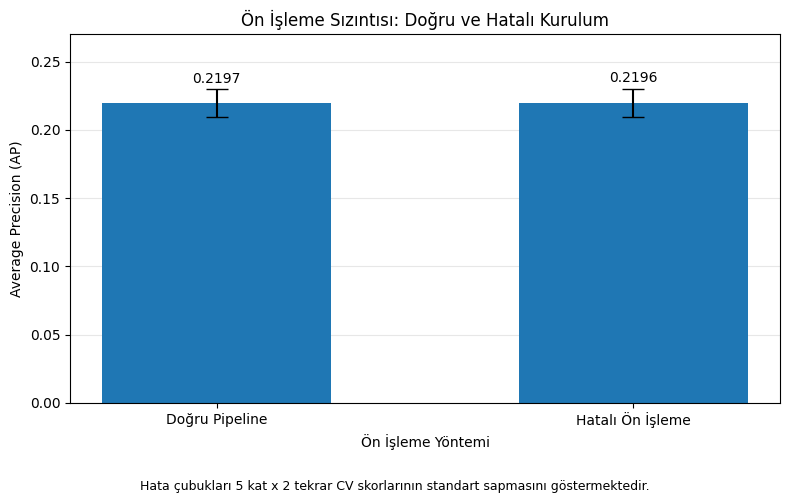

In [27]:
import matplotlib.pyplot as plt

# Modellerin isimleri
modeller = [
    "Doğru Pipeline",
    "Hatalı Ön İşleme"
]

# AP ortalamaları
ortalamalar = [
    skor_dogru_on_isleme.mean(),
    skor_yanlis_on_isleme.mean()
]

# AP standart sapmaları
standart_sapmalar = [
    skor_dogru_on_isleme.std(),
    skor_yanlis_on_isleme.std()
]

# Grafik oluştur
fig, ax = plt.subplots(figsize=(8, 5))

cubuklar = ax.bar(
    modeller,
    ortalamalar,
    yerr=standart_sapmalar,
    capsize=8,
    width=0.55
)

# Eksen ve grafik başlıkları
ax.set_title(
    "Ön İşleme Sızıntısı: Doğru ve Hatalı Kurulum"
)

ax.set_ylabel("Average Precision (AP)")
ax.set_xlabel("Ön İşleme Yöntemi")

ax.set_ylim(0, 0.27)

# Her çubuğun üzerine değer yaz
for i, cubuk in enumerate(cubuklar):
    ax.text(
        cubuk.get_x() + cubuk.get_width() / 2,
        ortalamalar[i] + standart_sapmalar[i] + 0.005,
        f"{ortalamalar[i]:.4f}",
        ha="center"
    )

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

# Grafiğin açıklaması
fig.text(
    0.5,
    0.01,
    "Hata çubukları 5 kat x 2 tekrar CV skorlarının "
    "standart sapmasını göstermektedir.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Yorum – Ön İşleme Kaynaklı Veri Sızıntısı

Bu deneyde ön işleme işlemlerinin çapraz doğrulama
öncesinde ve Pipeline içerisinde uygulanmasının
model başarımına etkisi karşılaştırılmıştır.

Doğru Pipeline yaklaşımında ortalama AP
0,2197 ± 0,0099 olarak bulunmuştur.

Ön işlemenin bütün geliştirme verisinde,
çapraz doğrulama öncesinde gerçekleştirildiği
hatalı kurulumda ise AP 0,2196 ± 0,0101 olmuştur.

İki kurulum arasındaki ortalama AP farkı
(hatalı - doğru) yaklaşık -0,0001'dir.

Sonuçlar, hatalı ön işlemenin bu deneyde
başarım artışı sağlamadığını göstermektedir.

Bununla birlikte hatalı kurulumda doğrulama
katlarının öznitelik bilgileri, ön işleme
parametrelerinin hesaplanmasına dahil edilmiştir.

Bu durum veri sızıntısı oluşturduğundan
hatalı kurulumun performans sonucu güvenilir
bir model değerlendirmesi olarak kabul edilemez.

Hata çubukları, tekrarlı çapraz doğrulama
skorlarının standart sapmasını göstermektedir.
Bunlar güven aralığı değildir.

Sonuç olarak ön işleme yöntemleri, model
başarımından bağımsız olarak, çapraz doğrulamanın
eğitim katları içerisinde öğrenilmelidir.